In [1]:
import nltk
import sklearn
import datasets
import huggingface_hub
import pyarrow

print("NLTK:", nltk.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Datasets:", datasets.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("PyArrow:", pyarrow.__version__)

print("\nAll libraries imported successfully!")

NLTK: 3.10.4
Scikit-learn: 1.9.1
Datasets: 5.2.0
Hugging Face Hub: 2.4.0
PyArrow: 26.0.1

All libraries imported successfully!


In [2]:
from datasets import load_dataset

dataset = load_dataset("fancyzhx/amazon_polarity")

print(dataset)

c:\Users\ANSHU SHAW\OneDrive\Desktop\RETAILMIND_AI\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ANSHU SHAW\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


amazon_polarity/train-00000-of-00004.par(…): reconstructing file:   0%|          |  0.00B /  260MB            

amazon_polarity/train-00000-of-00004.par(…): downloading bytes:           |  0.00B            

c:\Users\ANSHU SHAW\OneDrive\Desktop\RETAILMIND_AI\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ANSHU SHAW\.cache\huggingface\hub\datasets--fancyzhx--amazon_polarity. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


amazon_polarity/train-00001-of-00004.par(…): reconstructing file:   0%|          |  0.00B /  258MB            

amazon_polarity/train-00001-of-00004.par(…): downloading bytes:           |  0.00B            

... (5 outputs left out)

amazon_polarity/test-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3600000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/400000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'title', 'content'],
        num_rows: 3600000
    })
    test: Dataset({
        features: ['label', 'title', 'content'],
        num_rows: 400000
    })
})


In [3]:
import pandas as pd

train_sample = dataset["train"].shuffle(seed=42).select(range(40000))
test_sample = dataset["test"].shuffle(seed=42).select(range(10000))

train_df = pd.DataFrame(train_sample)
test_df = pd.DataFrame(test_sample)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining labels:")
print(train_df["label"].value_counts())

print("\nTesting labels:")
print(test_df["label"].value_counts())

train_df.head()


Training shape: (40000, 3)
Testing shape: (10000, 3)

Training labels:
label
0    20003
1    19997
Name: count, dtype: int64

Testing labels:
label
1    5042
0    4958
Name: count, dtype: int64


,label,title,content
0,0,Anyone who likes this better than the Pekinpah...,All the pretty people in this film. Even the R...
1,0,Author seems mentally unstable,I know that Tom Robbins has a loyal following ...
2,1,Spaetzle Noodles,This type of spaetzle maker is easier to manuv...
3,1,Cool product until the cats lost it . . . .,My cats seemed to be amused to work for their ...
4,1,Works as expected,I've had no problems running this with my Dell...


In [4]:
train_df = train_df[["content", "label"]].copy()
test_df = test_df[["content", "label"]].copy()

print("Sample review:")
print(train_df["content"].iloc[0])

print("\nSample label:")
print(train_df["label"].iloc[0])

Sample review:
All the pretty people in this film. Even the Rudy character played by Michael Madsen. This is adapted from a Jim Thompson novel for cryin' out loud! These are supposed to be marginal characters, not fashion models. Though McQueen and McGraw were attractive (but check out McQueen's crummy prison haircut) they were believable in the role. Baldwin and Bassinger seem like movie stars trying to act like hard cases. Action wise, the robbery scene in the Pekinpah version was about 100 times more exciting and suspenseful than anything in this re-make.

Sample label:
0


In [5]:
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

stop_words = set(stopwords.words("english"))

print("NLTK resources ready!")

[nltk_data] Downloading package punkt to C:\Users\ANSHU
[nltk_data]     SHAW\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\ANSHU
[nltk_data]     SHAW\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package punkt_tab to C:\Users\ANSHU
[nltk_data]     SHAW\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\ANSHU
[nltk_data]     SHAW\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


NLTK resources ready!


In [6]:
import re

def clean_text(text):
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove special characters and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Tokenization
    tokens = word_tokenize(text)

    # Remove stopwords
    tokens = [
        word for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    return " ".join(tokens)

In [7]:
train_df["cleaned_text"] = train_df["content"].apply(clean_text)
test_df["cleaned_text"] = test_df["content"].apply(clean_text)

print("Original review:")
print(train_df["content"].iloc[0])

print("\nCleaned review:")
print(train_df["cleaned_text"].iloc[0])


Original review:
All the pretty people in this film. Even the Rudy character played by Michael Madsen. This is adapted from a Jim Thompson novel for cryin' out loud! These are supposed to be marginal characters, not fashion models. Though McQueen and McGraw were attractive (but check out McQueen's crummy prison haircut) they were believable in the role. Baldwin and Bassinger seem like movie stars trying to act like hard cases. Action wise, the robbery scene in the Pekinpah version was about 100 times more exciting and suspenseful than anything in this re-make.

Cleaned review:
pretty people film even rudy character played michael madsen adapted jim thompson novel cryin loud supposed marginal characters fashion models though mcqueen mcgraw attractive check mcqueen crummy prison haircut believable role baldwin bassinger seem like movie stars trying act like hard cases action wise robbery scene pekinpah version times exciting suspenseful anything make


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train = tfidf.fit_transform(train_df["cleaned_text"])
X_test = tfidf.transform(test_df["cleaned_text"])

y_train = train_df["label"]
y_test = test_df["label"]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (40000, 20000)
Testing shape: (10000, 20000)


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_predictions))

print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Negative", "Positive"]
))

Logistic Regression Accuracy: 0.8642
              precision    recall  f1-score   support

    Negative       0.87      0.86      0.86      4958
    Positive       0.86      0.87      0.87      5042

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



In [10]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(random_state=42)

svm_model.fit(X_train, y_train)

svm_predictions = svm_model.predict(X_test)

print("Linear SVM Accuracy:",
      accuracy_score(y_test, svm_predictions))

print(classification_report(
    y_test,
    svm_predictions,
    target_names=["Negative", "Positive"]
))

Linear SVM Accuracy: 0.8543
              precision    recall  f1-score   support

    Negative       0.86      0.85      0.85      4958
    Positive       0.85      0.86      0.86      5042

    accuracy                           0.85     10000
   macro avg       0.85      0.85      0.85     10000
weighted avg       0.85      0.85      0.85     10000



                 Model  Accuracy
0  Logistic Regression    0.8642
1           Linear SVM    0.8543


NameError: name 'plt' is not defined

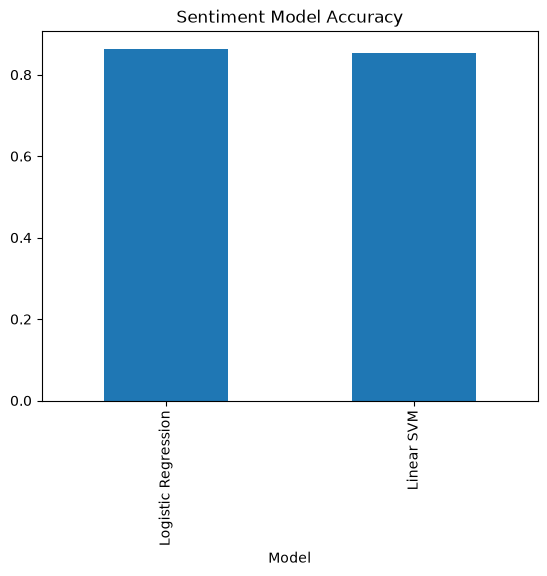

In [14]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Linear SVM"],
    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, svm_predictions)
    ]
})

print(comparison)

comparison.plot(
    x="Model",
    y="Accuracy",
    kind="bar",
    legend=False,
    title="Sentiment Model Accuracy"
)

plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.show()

In [15]:
if accuracy_score(y_test, lr_predictions) >= accuracy_score(y_test, svm_predictions):
    best_model = lr_model
    best_predictions = lr_predictions
    best_model_name = "Logistic Regression"
else:
    best_model = svm_model
    best_predictions = svm_predictions
    best_model_name = "Linear SVM"

print("Best Model:", best_model_name)
print("Best Accuracy:", accuracy_score(y_test, best_predictions))

Best Model: Logistic Regression
Best Accuracy: 0.8642


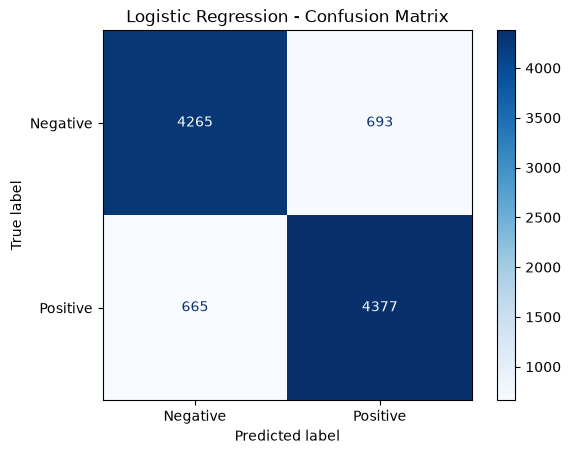

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, best_predictions)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
).plot(cmap="Blues")

plt.title(f"{best_model_name} - Confusion Matrix")
plt.show()

In [20]:
import numpy as np

feature_names = np.array(tfidf.get_feature_names_out())

coefficients = best_model.coef_[0]

positive_indices = np.argsort(coefficients)[-15:][::-1]
negative_indices = np.argsort(coefficients)[:15]

print("Top Positive Words:")
print(feature_names[positive_indices])

print("\nTop Negative Words:")
print(feature_names[negative_indices])

Top Positive Words:
['great' 'excellent' 'love' 'awesome' 'best' 'easy' 'wonderful' 'perfect'
 'amazing' 'pleased' 'loves' 'highly' 'favorite' 'well' 'enjoyed']

Top Negative Words:
['waste' 'worst' 'disappointed' 'boring' 'poor' 'terrible' 'disappointing'
 'disappointment' 'return' 'horrible' 'returned' 'poorly' 'nothing'
 'money' 'unfortunately']


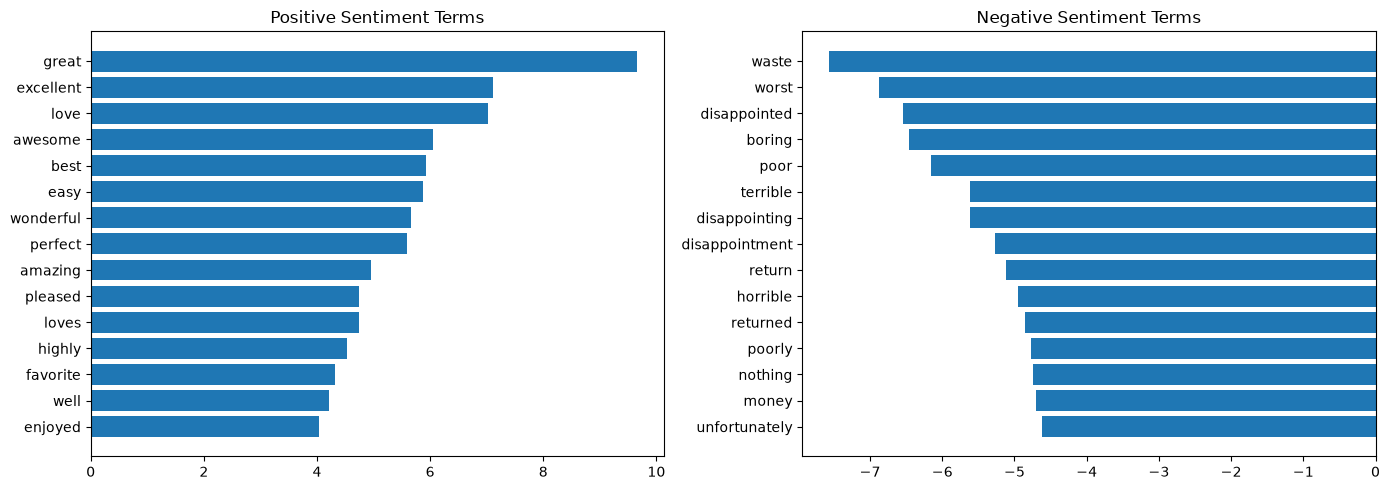

In [21]:
positive_words = feature_names[positive_indices]
negative_words = feature_names[negative_indices]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(
    positive_words[::-1],
    coefficients[positive_indices][::-1]
)
axes[0].set_title("Positive Sentiment Terms")

axes[1].barh(
    negative_words[::-1],
    coefficients[negative_indices][::-1]
)
axes[1].set_title("Negative Sentiment Terms")

plt.tight_layout()
plt.show()


In [22]:
def predict_sentiment(review):

    cleaned = clean_text(review)

    vector = tfidf.transform([cleaned])

    prediction = best_model.predict(vector)[0]

    sentiment = "Positive" if prediction == 1 else "Negative"

    return sentiment

In [23]:
reviews = [
    "This product is excellent and works perfectly",
    "Very poor quality and completely disappointing",
    "Amazing product, worth every penny",
    "Terrible experience, I would not recommend it",
    "The product is okay, nothing special"
]

for review in reviews:
    print("Review:", review)
    print("Sentiment:", predict_sentiment(review))
    print("-" * 60)

Review: This product is excellent and works perfectly
Sentiment: Positive
------------------------------------------------------------
Review: Very poor quality and completely disappointing
Sentiment: Negative
------------------------------------------------------------
Review: Amazing product, worth every penny
Sentiment: Positive
------------------------------------------------------------
Review: Terrible experience, I would not recommend it
Sentiment: Negative
------------------------------------------------------------
Review: The product is okay, nothing special
Sentiment: Negative
------------------------------------------------------------


In [24]:
import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(tfidf, MODEL_DIR / "day12_tfidf.pkl")
joblib.dump(best_model, MODEL_DIR / "day12_sentiment_model.pkl")
joblib.dump(stop_words, MODEL_DIR / "day12_stopwords.pkl")

print("All NLP components saved successfully!")

All NLP components saved successfully!


In [25]:
for file in MODEL_DIR.glob("day12_*"):
    print(
        file.name,
        "-",
        round(file.stat().st_size / 1024, 2),
        "KB"
    )

day12_sentiment_model.pkl - 157.09 KB
day12_stopwords.pkl - 1.43 KB
day12_tfidf.pkl - 756.39 KB


In [26]:
loaded_tfidf = joblib.load(
    MODEL_DIR / "day12_tfidf.pkl"
)

loaded_model = joblib.load(
    MODEL_DIR / "day12_sentiment_model.pkl"
)

test_review = "Excellent quality and very fast delivery"

cleaned = clean_text(test_review)
vector = loaded_tfidf.transform([cleaned])

prediction = loaded_model.predict(vector)[0]

print("Review:", test_review)
print("Prediction:", "Positive" if prediction == 1 else "Negative")
print("Saved model loaded successfully!")

Review: Excellent quality and very fast delivery
Prediction: Positive
Saved model loaded successfully!
